In [4]:
import pandas as pd
import numpy as np
from torch.utils.data import Dataset,DataLoader
import torch 
import matplotlib.pyplot as plt 
from PIL import Image
from pathlib import Path
import torchvision.transforms as transforms
import os

In [15]:
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

In [4]:
class FashionMNISTDataset(Dataset):
    def __init__(self,data,transform=None):
        self.data=data
        self.transform=transform
        self.labels=torch.tensor(data.iloc[:,0].values,dtype=torch.long)
        features=data.iloc[:,1:].values
        features=features.reshape(-1,1,28,28)/255.0
        self.features=torch.tensor(features,dtype=torch.float32)


    def __len__(self):
        return len(self.labels)

    def __getitem__(self,idx):
        x=self.features[idx]
        y=self.labels[idx]

        if self.transform:
            x=self.transform(x)
        return x,y
        

In [5]:
train_data=pd.read_csv('Dataset/fashion-mnist_train.csv')
test_data=pd.read_csv('Dataset/fashion-mnist_test.csv')

In [5]:
train_dataset=FashionMNISTDataset(train_data)
test_dataset=FashionMNISTDataset(test_data)

In [6]:
train_loader=DataLoader(train_dataset,
                        batch_size=32,
                        shuffle=True
                       )
test_loader=DataLoader(test_dataset,
                       batch_size=32,
                       shuffle=False
                      )


In [8]:
from cnn_modle import CNN

In [8]:
model=CNN(num_classes=10)

In [9]:
import torch.optim as optim
import torch.nn as nn
from tqdm.auto import tqdm

In [10]:

optimizer=optim.Adam(model.parameters(),lr=0.001)
loss_fn=nn.CrossEntropyLoss()

In [11]:
epochs=10
train_loss_history=[]
test_loss_history=[]
for epoch in tqdm(range(epochs),desc="Training Epochs"):
    running_loss=0.0
    model.train()
    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{epochs}",
        leave=False
    )
    for image,label in train_loader:
        pred=model(image)
        loss=loss_fn(pred,label)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss+=loss.item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")
    epoch_loss=running_loss/len(train_loader)
    train_loss_history.append(epoch_loss)
    if epoch % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")
    

Training Epochs:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch 1/10:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch [1/10], Loss: 0.4640


Epoch 2/10:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch 3/10:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch 4/10:   0%|          | 0/1875 [00:00<?, ?it/s]

... (2 outputs left out)

Epoch 7/10:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch 8/10:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch 9/10:   0%|          | 0/1875 [00:00<?, ?it/s]

Epoch 10/10:   0%|          | 0/1875 [00:00<?, ?it/s]

In [16]:
model.eval()
test_loss=0.0
correct=0
total=0
with torch.no_grad():
    for image ,labels in test_loader:
        outputs=model(image)
        loss=loss_fn(outputs,labels)
        test_loss+=loss.item()*image.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    avg_test_loss = test_loss / total
    test_accuracy = (correct / total) * 100
    
    print(f"Test Loss: {avg_test_loss:.4f} | Test Accuracy: {test_accuracy:.2f}%")
        
    

Test Loss: 0.2346 | Test Accuracy: 92.02%


In [17]:
torch.save(model.state_dict(),"Samall_fashionMNIST_model.pth")

In [9]:
def predict_new_image(model,image_path):
    image=Image.open(image_path).convert('L')
    transform=transforms.Compose([
        transforms.Resize((28,28)),
        transforms.ToTensor(),
        transforms.Normalize( (0.5,),(0.5)),
        
    ])
    image_tensor=transform(image)
    image_tensor=image_tensor.unsqueeze(0)
    model.eval()
    with torch.no_grad():
        pred=model(image_tensor)
        predicted_class=torch.argmax(pred).item()

    return predicted_class
        

In [11]:
new_model=CNN()
state_dict=torch.load('Samall_fashionMNIST_model.pth',weights_only=True)
new_model.load_state_dict(state_dict)

<All keys matched successfully>

In [20]:
image_path1 = r"Testing\test_image.jfif"

pred1 = predict_new_image(new_model, image_path1)

print("Predicted Class:", class_names.get(pred1))

Predicted Class: Bag


In [51]:
class_names.get(7)

'Sneaker'

In [21]:
image_path2 = r"Testing\image.jfif"

pred2 = predict_new_image(new_model, image_path2)


print("Predicted Class:", class_names.get(pred2))

Predicted Class: Bag


In [22]:
image_path3 = r"Testing\boot.jfif"

pred3 = predict_new_image(new_model, image_path3)


print("Predicted Class:", class_names.get(pred3))

Predicted Class: Bag


In [19]:
image_path = r"Testing\bag.jfif"

pred4 = predict_new_image(new_model, image_path)


print("Predicted Class:", class_names.get(pred4))

Predicted Class: Bag


In [23]:
image_path5 = r"Testing\dress.jfif"

pred5 = predict_new_image(new_model, image_path5)


print("Predicted Class:", class_names.get(pred5))

Predicted Class: T-shirt/top


[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


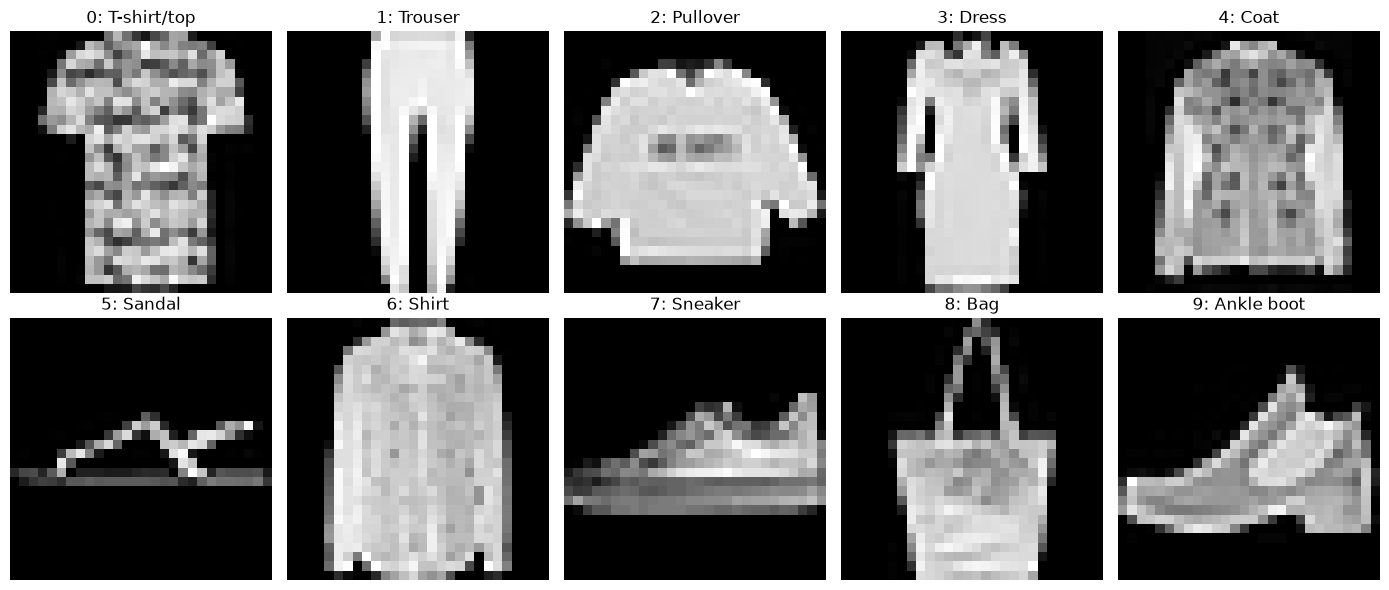

In [13]:
print(sorted(train_data['label'].unique()))
print(train_data['label'].value_counts().sort_index())
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for label, ax in enumerate(axes.flat):

    sample = train_data[train_data['label'] == label].iloc[0]

    pixels = sample.drop('label').values.reshape(28, 28)

    ax.imshow(pixels, cmap='gray')
    ax.set_title(f"{label}: {class_names[label]}")
    ax.axis('off')

plt.tight_layout()
plt.show()

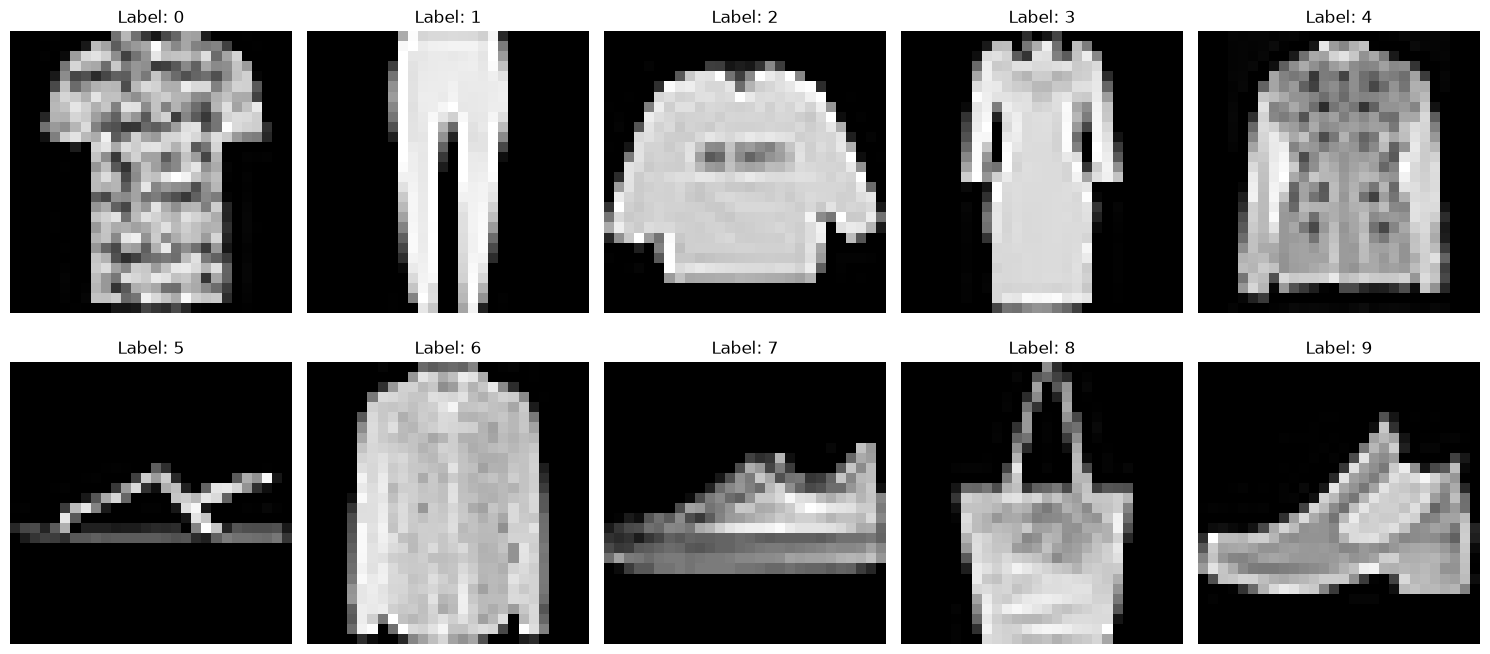

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for label, ax in enumerate(axes.flat):

    sample = train_data[train_data['label'] == label].iloc[0]

    image = sample.drop('label').values.reshape(28, 28)

    ax.imshow(image, cmap='gray')
    ax.set_title(f"Label: {label}")
    ax.axis('off')

plt.tight_layout()
plt.show()